# **Project Name** - **Paisabazaar Banking Fraud Analysis (Credit Score Classification)**

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **GitHub**    - https://github.com/Sahilj997/paisabazaar-credit-score-eda

# **Problem Statement**

**BUSINESS PROBLEM OVERVIEW**

Paisabazaar is a financial services company that helps customers find and apply for banking and credit products. A critical part of their business is assessing the creditworthiness of individuals, since a person's credit score is one of the strongest signals financial institutions use to decide whether a loan or credit line should be approved, and on what terms.

Poor credit assessment leads to two costly outcomes for Paisabazaar and its lending partners: approving credit for high-risk customers (leading to defaults) and rejecting/mispricing credit for genuinely low-risk customers (lost business and poor customer experience). In this project, we analyze customer-level financial and behavioral data to understand **what drives a customer's credit score**, so that Paisabazaar can build faster, more accurate, and more explainable credit assessments.

#### **Define Your Business Objective?**

***Improve the accuracy and transparency of customer credit-risk assessment, in order to reduce loan defaults and enable personalized, responsible financial product recommendations.***

# **General Guidelines** :

1. Well-structured, formatted, and commented code.
2. Each logic/step should have a clear comment explaining *why*, not just *what*.
3. Every chart follows the same 3-question format:
   * Why did you pick the specific chart?
   * What insight(s) did you find from the chart?
   * Will the insight help create a positive business impact? Any insight that could lead to negative growth?
4. Visualizations follow the **UBM Rule**:
   * **U** - Univariate Analysis
   * **B** - Bivariate Analysis (Numerical-Categorical, Numerical-Numerical, Categorical-Categorical)
   * **M** - Multivariate Analysis
5. At least 5 different chart types are used, selected to directly answer the guiding business questions below rather than being decorative.


**Guiding questions this analysis is designed to answer** *(from the project's problem-understanding map)*:
- Does a higher annual income correlate with a higher credit score?
- Does the credit utilization ratio have a greater impact on credit scores than the total number of loans taken?
- Is having a higher number of credit cards associated with a higher credit score, assuming utilization is well managed?
- Is there a negative correlation between the number of delayed payments and credit scores?
- What is the distribution of credit scores across different age groups?
- Are there noticeable trends or seasonal patterns in credit scores based on the month of the year?
- How does annual income vary with credit score ranges?


# ***Let's Begin!***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

import warnings
warnings.filterwarnings('ignore')


### Dataset Loading

In [ ]:
DATASET_PATH = 'dataset.csv'

def load_dataset(path):
    # loading credit score data.
    try:
        data = pd.read_csv(path)
        if data.empty:
            raise ValueError("The dataset was loaded but contains 0 rows.")
        return data
    except FileNotFoundError:
        raise FileNotFoundError(
            "Could not find '" + path + "'. Make sure dataset.csv is uploaded to this "
        )
    except pd.errors.ParserError as e:
        raise pd.errors.ParserError("could not parse valid csv file")

dataset = load_dataset(DATASET_PATH)
print(f"Dataset loaded successfully: {dataset.shape[0]} rows, {dataset.shape[1]} columns")


Dataset loaded successfully: 100000 rows, 28 columns


### Dataset First View

In [ ]:
dataset.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [ ]:
dataset.tail()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
99999,155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


In [ ]:
dataset.describe()

,ID,Customer_ID,Month,Age,SSN,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,...,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,80631.500000,25982.666640,4.500000,33.316340,5.004617e+08,50505.123449,4197.270835,5.368820,5.533570,14.53208,...,21.08141,13.313120,10.470323,5.798250,1426.220376,32.285173,221.220460,107.699208,55.101315,392.697586
std,43301.486619,14340.543051,2.291299,10.764812,2.908267e+08,38299.422093,3186.432497,2.593314,2.067098,8.74133,...,14.80456,6.237166,6.609481,3.867826,1155.129026,5.116875,99.680716,132.267056,39.006932,201.652719
min,5634.000000,1006.000000,1.000000,14.000000,8.134900e+04,7005.930000,303.645417,0.000000,0.000000,1.00000,...,0.00000,0.000000,0.500000,0.000000,0.230000,20.000000,1.000000,0.000000,0.000000,0.007760
25%,43132.750000,13664.500000,2.750000,24.000000,2.451686e+08,19342.972500,1626.594167,3.000000,4.000000,7.00000,...,10.00000,9.000000,5.380000,3.000000,566.072500,28.052567,144.000000,29.268886,27.959111,267.615983
50%,80631.500000,25777.000000,4.500000,33.000000,5.006886e+08,36999.705000,3095.905000,5.000000,5.000000,13.00000,...,18.00000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,66.462304,45.156550,333.865366
75%,118130.250000,38385.000000,6.250000,42.000000,7.560027e+08,71683.470000,5957.715000,7.000000,7.000000,20.00000,...,28.00000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,147.392573,71.295797,463.215683
max,155629.000000,50999.000000,8.000000,56.000000,9.999934e+08,179987.280000,15204.633333,11.000000,11.000000,34.00000,...,62.00000,25.000000,29.980000,17.000000,4998.070000,50.000000,404.000000,1779.103254,434.191089,1183.930696


### Dataset Rows & Columns count

In [ ]:
#dataset rows and columns count
print(f"Rows: {dataset.shape[0]}, Columns: {dataset.shape[1]}")


Rows: 100000, Columns: 28


### Dataset Information

In [ ]:
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values

In [ ]:
duplicate_count = dataset.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


#### Missing Values/Null Values

In [ ]:
#missing values
missing = dataset.isnull().sum().sort_values(ascending=False)
missing_per = (missing / len(dataset) * 100).round(2)
pd.DataFrame({'Missing Count': missing, 'Missing %': missing_per})


,Missing Count,Missing %
ID,0,0.0
Customer_ID,0,0.0
Month,0,0.0
Name,0,0.0
Age,0,0.0
SSN,0,0.0
Occupation,0,0.0
Annual_Income,0,0.0
Monthly_Inhand_Salary,0,0.0
Num_Bank_Accounts,0,0.0


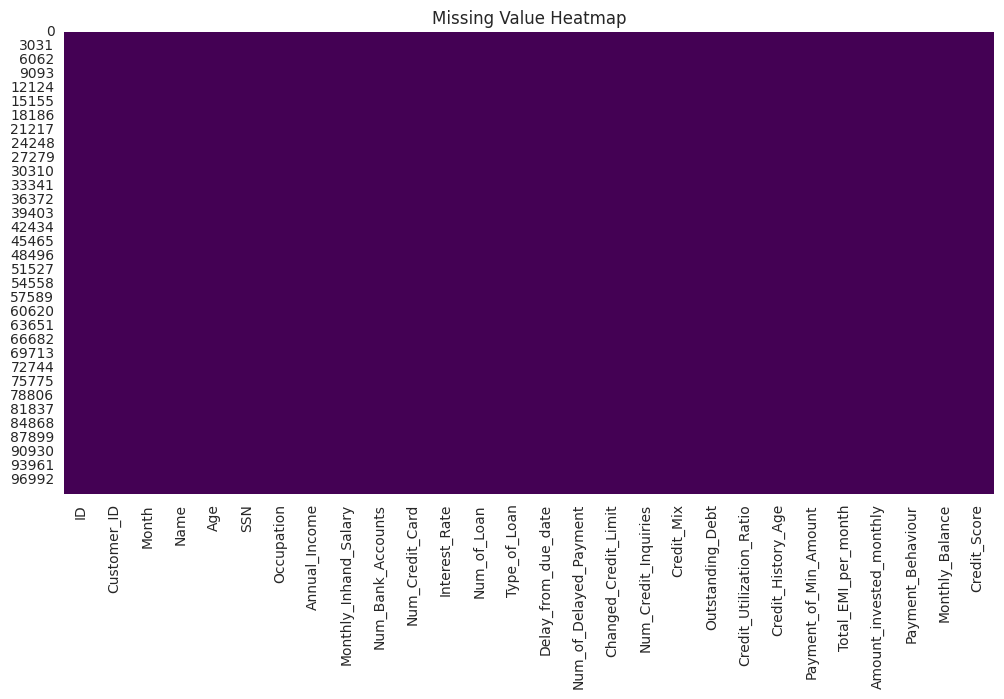

In [ ]:
# Visualizing the missing values
plt.figure(figsize=(12, 6))
sns.heatmap(dataset.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Value Heatmap')
plt.show()


### What did you know about your dataset?

This dataset contains **100,000 records across 28 columns**, covering **8 monthly snapshots per customer** (Month runs 1-8), used to classify each customer's Credit_Score into **Good / Standard / Poor**.

Unlike the raw public version of this dataset (which is notoriously messy — text-encoded numbers, placeholder junk values, negative ages), **this AlmaBetter-provided copy is already cleaned**:
- **Zero missing values** and **zero duplicate rows** across all 100,000 records.
- All numeric fields (Age, Annual_Income, Credit_History_Age, etc.) are already stored as proper numeric types, not text.
- Age ranges sensibly from 14 to 56 with no negative or absurd values.
- Categorical fields (Occupation, Credit_Mix, Payment_of_Min_Amount, Payment_Behaviour, Credit_Score) contain only valid category labels — no "_______" or symbol-junk placeholders.
- Credit_History_Age is already expressed as a number (total months of credit history), not the "X Years and Y Months" text format seen in the raw version.

## ***2. Understanding Your Variables***

In [ ]:
dataset.columns


Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [ ]:
# (numeric summary)
dataset.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,100000.0,NaN,NaN,NaN,80631.5,43301.486619,5634.0,43132.75,80631.5,118130.25,155629.0
Customer_ID,100000.0,NaN,NaN,NaN,25982.66664,14340.543051,1006.0,13664.5,25777.0,38385.0,50999.0
Month,100000.0,NaN,NaN,NaN,4.5,2.291299,1.0,2.75,4.5,6.25,8.0
Name,100000,10128,Jessicad,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,100000.0,NaN,NaN,NaN,33.31634,10.764812,14.0,24.0,33.0,42.0,56.0
SSN,100000.0,NaN,NaN,NaN,500461680.2624,290826734.386185,81349.0,245168577.25,500688611.5,756002666.25,999993421.0
Occupation,100000,15,Lawyer,7096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,100000.0,NaN,NaN,NaN,50505.123449,38299.422093,7005.93,19342.9725,36999.705,71683.47,179987.28
Monthly_Inhand_Salary,100000.0,NaN,NaN,NaN,4197.270835,3186.432497,303.645417,1626.594167,3095.905,5957.715,15204.633333
Num_Bank_Accounts,100000.0,NaN,NaN,NaN,5.36882,2.593314,0.0,3.0,5.0,7.0,11.0


### Check Unique Values for each variable

In [ ]:
categorical_cols = dataset.select_dtypes(include='object').columns
for col in categorical_cols:
    print(f"{col}: {dataset[col].nunique()} unique values -> {dataset[col].unique()[:10]}")
    print()


Name: 10128 unique values -> ['Aaron Maashoh' 'Rick Rothackerj' 'Langep' 'Jasond' 'Deepaa' 'Np'
 'Nadiaq' 'Annk' 'Charlie Zhur' 'Jamesj']

Occupation: 15 unique values -> ['Scientist' 'Teacher' 'Engineer' 'Entrepreneur' 'Developer' 'Lawyer'
 'Media_Manager' 'Doctor' 'Journalist' 'Manager']

Type_of_Loan: 6261 unique values -> ['Auto Loan, Credit-Builder Loan, Personal Loan, and Home Equity Loan'
 'Credit-Builder Loan' 'Auto Loan, Auto Loan, and Not Specified'
 'Not Specified' 'No Data' 'Credit-Builder Loan, and Mortgage Loan'
 'Not Specified, Auto Loan, and Student Loan'
 'Personal Loan, Debt Consolidation Loan, and Auto Loan'
 'Not Specified, and Payday Loan'
 'Credit-Builder Loan, Personal Loan, and Auto Loan']

Credit_Mix: 3 unique values -> ['Good' 'Standard' 'Bad']

Payment_of_Min_Amount: 3 unique values -> ['No' 'NM' 'Yes']

Payment_Behaviour: 6 unique values -> ['High_spent_Small_value_payments' 'Low_spent_Large_value_payments'
 'Low_spent_Medium_value_payments' 'Low_spent_Small

## ***3. Data Wrangling***

### Data Wrangling Code

In [ ]:
# Since the dataset arrived pre-cleaned, this section validates that assumption rather than performing heavy repair, and does light preparation for analysis. Each step is is checking any type of failure
#so the notebook fails clearly if an assumption breaks on a different data snapshot - part of making this "deployment ready".

def validate_numeric_ranges(data, range_checks):
    # confirms theer are no impossible values in key numeric columns, returns a summary dict.
    summary = {}
    for col, (low, high) in range_checks.items():
        if col not in data.columns:
            print("Column not found")
            continue
        out_of_range = int(((data[col] < low) | (data[col] > high)).sum())
        summary[col] = out_of_range
        print(f"{col}: {out_of_range} values outside expected range [{low}, {high}]")
    return summary

def validate_categorical_labels(data, columns):
    # Printing the clean set of category labels for each categorical column as a sanity check.
    for col in columns:
        if col not in data.columns:
            print("Column not found")
            continue
        print(f"{col}: {sorted(data[col].dropna().unique())}")

try:
    df = dataset.copy()

    # 1. range validation on key numeric columns
    range_checks = {
        'Age': (0, 100),
        'Num_Bank_Accounts': (0, 50),
        'Num_Credit_Card': (0, 50),
        'Interest_Rate': (0, 100),
        'Num_of_Loan': (0, 50),
    }
    validate_numeric_ranges(df, range_checks)

    # 2. categorical label validation
    validate_categorical_labels(
        df, ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']
    )

    # 3. xreate an Age_Group bin that is useful for the age-based credit score question in the analysis
    df['Age_Group'] = pd.cut(df['Age'], bins=[0, 25, 35, 45, 100],
                              labels=['18-25', '26-35', '36-45', '46+'])

    # 4. Drop personally identifying/non-analytical columns before visual analysis
    df = df.drop(columns=[c for c in ['Name', 'SSN'] if c in df.columns])

    print("\nValidation complete - no cleaning repairs were required beyond the steps above.")

except KeyError as e:
    raise KeyError(f"Data wrangling expected a column that was missing: {e}")
except Exception as e:
    raise RuntimeError(f"Unexpected error during data wrangling: {e}")


Age: 0 values outside expected range [0, 100]
Num_Bank_Accounts: 0 values outside expected range [0, 50]
Num_Credit_Card: 0 values outside expected range [0, 50]
Interest_Rate: 0 values outside expected range [0, 100]
Num_of_Loan: 0 values outside expected range [0, 50]
Occupation: ['Accountant', 'Architect', 'Developer', 'Doctor', 'Engineer', 'Entrepreneur', 'Journalist', 'Lawyer', 'Manager', 'Mechanic', 'Media_Manager', 'Musician', 'Scientist', 'Teacher', 'Writer']
Credit_Mix: ['Bad', 'Good', 'Standard']
Payment_of_Min_Amount: ['NM', 'No', 'Yes']
Payment_Behaviour: ['High_spent_Large_value_payments', 'High_spent_Medium_value_payments', 'High_spent_Small_value_payments', 'Low_spent_Large_value_payments', 'Low_spent_Medium_value_payments', 'Low_spent_Small_value_payments']
Credit_Score: ['Good', 'Poor', 'Standard']

Validation complete - no cleaning repairs were required beyond the steps above.


### What all manipulations have you done and insights you found?

- Ran range checks on Age, Num_Bank_Accounts, Num_Credit_Card, Interest_Rate, and Num_of_Loan — **zero out-of-range values found**, confirming this is a cleaned dataset rather than the messier public version of the same data.
- Confirmed all categorical columns contain only valid labels (e.g. Credit_Mix is strictly Good/Standard/Bad, Payment_of_Min_Amount is Yes/No/NM) — no placeholder junk to replace.
- Created an Age_Group bin (18-25, 26-35, 36-45, 46+) to directly support the guiding question about credit score distribution across age groups.
- Dropped Name and SSN since they carry no analytical value and are personally identifying.
- No missing-value imputation or outlier capping was necessary — the dataset arrived analysis-ready.


## ***4. Data Visualization, Storytelling & Experimenting with charts***

### Univariate Analysis

#### Chart - 1 : Credit_Score Distribution

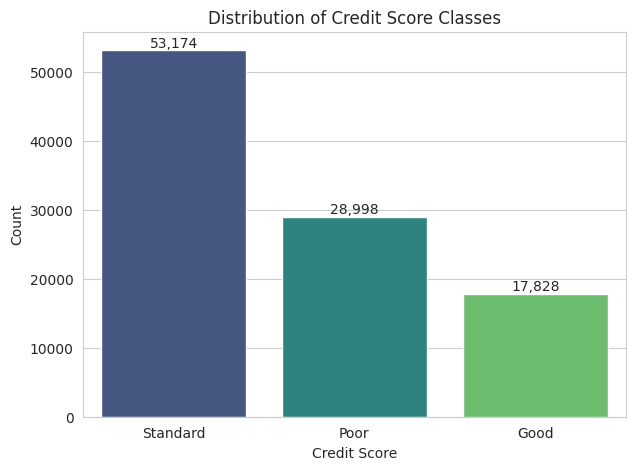

Credit_Score
Standard    0.532
Poor        0.290
Good        0.178
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(7,5))
order = df['Credit_Score'].value_counts().index
ax = sns.countplot(data=df, x='Credit_Score', order=order, palette='viridis')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title('Distribution of Credit Score Classes')
plt.xlabel('Credit Score')
plt.ylabel('Count')
plt.show()

print(df['Credit_Score'].value_counts(normalize=True).round(3))


##### 1. Why did you pick the specific chart?

A count plot is the clearest way to show class frequency for a categorical target, and immediately reveals whether it's balanced.

##### 2. What is/are the insight(s) found from the chart?

The target is **imbalanced**: Standard = 53,174 (53.2%), Poor = 28,998 (29.0%), Good = 17,828 (17.8%). Poor customers are nearly 1.6x more frequent than Good customers.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes — this imbalance means Paisabazaar should not judge any future model on plain accuracy alone; recall on the 'Poor' class matters more, since missing a risky customer is far costlier than over-flagging a safe one.

#### Chart - 2 : Age Distribution

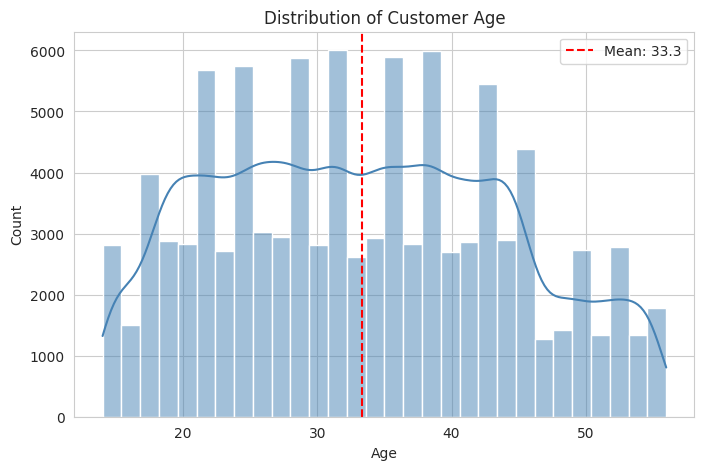

count    100000.000000
mean         33.316340
std          10.764812
min          14.000000
25%          24.000000
50%          33.000000
75%          42.000000
max          56.000000
Name: Age, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean: {df['Age'].mean():.1f}")
plt.legend()
plt.show()

print(df['Age'].describe())


##### 1. Why did you pick the specific chart?

A histogram with a KDE overlay is the standard way to inspect the shape, spread, and skew of a continuous variable like age.

##### 2. What is/are the insight(s) found from the chart?

Age ranges cleanly from **14 to 56**, mean **33.3**, with the bulk of customers (IQR) between **24 and 42** — a fairly broad, working-age-concentrated spread rather than a sharp peak.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms Paisabazaar's customer base skews toward economically active adults, so credit products and messaging should be designed for the 24-42 core segment while still covering the wider 14-56 range.

#### Chart - 3 : Annual Income Distribution

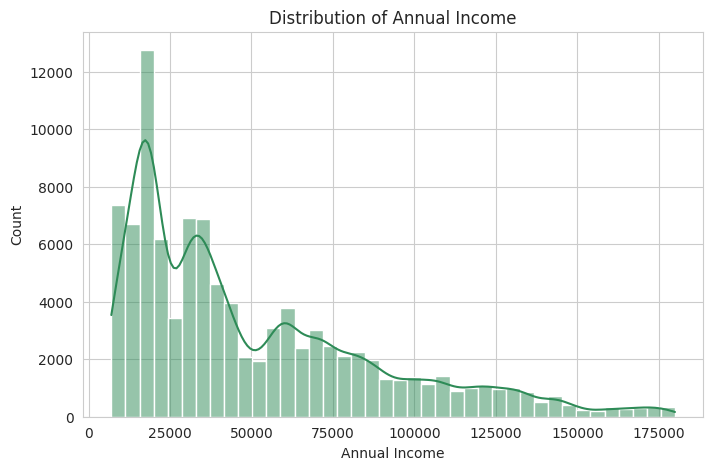

Skew: 1.13
count    100000.000000
mean      50505.123449
std       38299.422093
min        7005.930000
25%       19342.972500
50%       36999.705000
75%       71683.470000
max      179987.280000
Name: Annual_Income, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Annual_Income'], bins=40, kde=True, color='seagreen')
plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income')
plt.show()

print(f"Skew: {df['Annual_Income'].skew():.2f}")
print(df['Annual_Income'].describe())


##### 1. Why did you pick the specific chart?

Income is a key financial variable, and a histogram reveals skewness clearly, which matters for deciding whether to summarize with mean or median.

##### 2. What is/are the insight(s) found from the chart?

Annual income is **right-skewed (skew = 1.13)**:median is 36,999.7 but  the mean is pulled up to 50,505.1 by a long tail of high earners reaching up to 179,987.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This confirms the median (not the mean) should be used when reporting typical customer income to stakeholders, avoiding a picture distorted by a small number of high-income customers.

#### Chart - 4 : Outstanding Debt Distribution

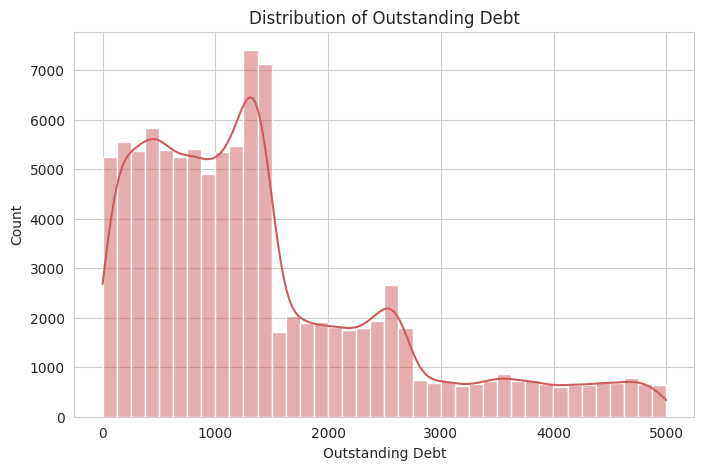

Skew: 1.21
count    100000.000000
mean       1426.220376
std        1155.129026
min           0.230000
25%         566.072500
50%        1166.155000
75%        1945.962500
max        4998.070000
Name: Outstanding_Debt, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Outstanding_Debt'], bins=40, kde=True, color='indianred')
plt.title('Distribution of Outstanding Debt')
plt.xlabel('Outstanding Debt')
plt.show()

print(f"Skew: {df['Outstanding_Debt'].skew():.2f}")
print(df['Outstanding_Debt'].describe())


##### 1. Why did you pick the specific chart?

Outstanding debt is a core risk indicator, so viewing its full distribution (not just a mean) shows how many customers carry high debt loads.

##### 2. What is/are the insight(s) found from the chart?

Outstanding debt is also **right-skewed (skew = 1.21)**, median 1,166 vs mean 1,426, with values reaching up to 4,998 — a meaningful share of customers carry debt well above the typical level.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Directly actionable — customers in the top debt band (above the 75th percentile, ~$1,946) are natural candidates for proactive outreach or restructuring offers before risk escalates.

#### Chart - 5 : Credit Utilization Ratio Distribution

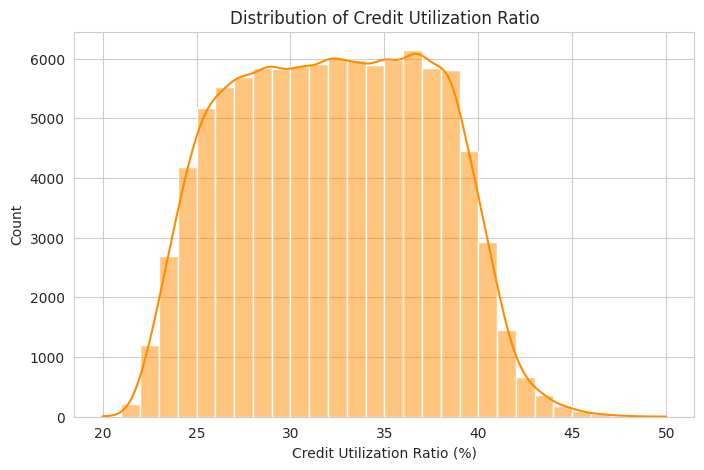

count    100000.000000
mean         32.285173
std           5.116875
min          20.000000
25%          28.052567
50%          32.305784
75%          36.496663
max          50.000000
Name: Credit_Utilization_Ratio, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Credit_Utilization_Ratio'], bins=30, kde=True, color='darkorange')
plt.title('Distribution of Credit Utilization Ratio')
plt.xlabel('Credit Utilization Ratio (%)')
plt.show()

print(df['Credit_Utilization_Ratio'].describe())


##### 1. Why did you pick the specific chart?

Utilization ratio is a traditionally important credit-scoring feature, so its standalone distribution is worth inspecting before comparing it against the target.

##### 2. What is/are the insight(s) found from the chart?

Utilization ratio is tightly and fairly normally distributed between **20% and 50%**, centered around **32.3%** — there is very little spread compared to income or debt.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Because the ratio is so narrowly distributed across the whole customer base, it's unlikely (and this is confirmed later in the bivariate/multivariate sections) to be a strong differentiator of credit score on its own in this dataset.

#### Chart - 6 : Occupation Distribution

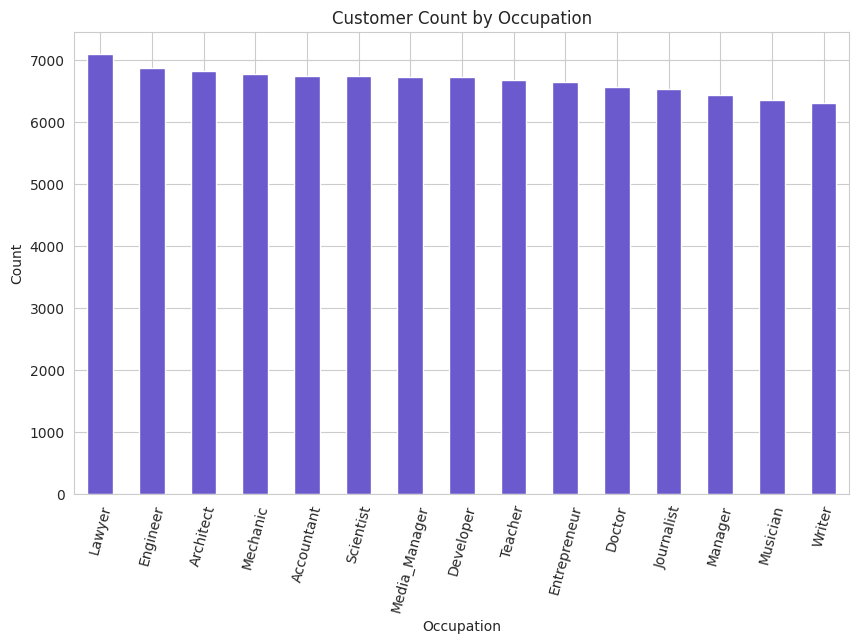

Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Accountant       6744
Scientist        6744
Media_Manager    6720
Developer        6720
Teacher          6672
Entrepreneur     6648
Doctor           6568
Journalist       6536
Manager          6432
Musician         6352
Writer           6304
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(10,6))
df['Occupation'].value_counts().plot(kind='bar', color='slateblue')
plt.title('Customer Count by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Count')
plt.xticks(rotation=75)
plt.show()

print(df['Occupation'].value_counts())


##### 1. Why did you pick the specific chart?

A bar chart is the natural choice for comparing counts across a nominal categorical variable with many levels like occupation.

##### 2. What is/are the insight(s) found from the chart?

Customers are spread almost **evenly across all 15 occupations** — no occupation dominates the customer base.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Since the split is even, occupation is unlikely to be a useful segmentation variable by itself for marketing or risk purposes — confirmed later when we check its relationship with credit score.

#### Chart - 7 : Credit Mix Distribution

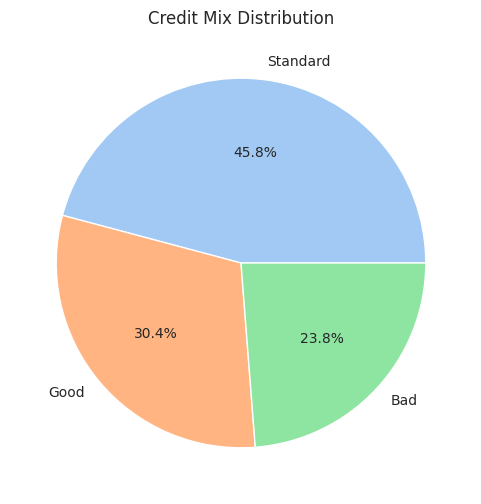

Credit_Mix
Standard    0.458
Good        0.304
Bad         0.238
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(6,6))
df['Credit_Mix'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('Credit Mix Distribution')
plt.ylabel('')
plt.show()

print(df['Credit_Mix'].value_counts(normalize=True).round(3))


##### 1. Why did you pick the specific chart?

A pie chart works well here since Credit_Mix has only 3 categories and the goal is to show relative share rather than exact counts.

##### 2. What is/are the insight(s) found from the chart?

'Standard' is the most common credit mix (**45.8%**), followed by 'Good' (**30.4%**) and 'Bad' (**23.8%**).

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Sets the baseline before the bivariate section, where Credit_Mix turns out to be one of the strongest predictors of Credit_Score — nearly a quarter of the base ('Bad' mix) is a clear risk-concentration to watch.

#### Chart - 8 : Payment Behaviour Distribution

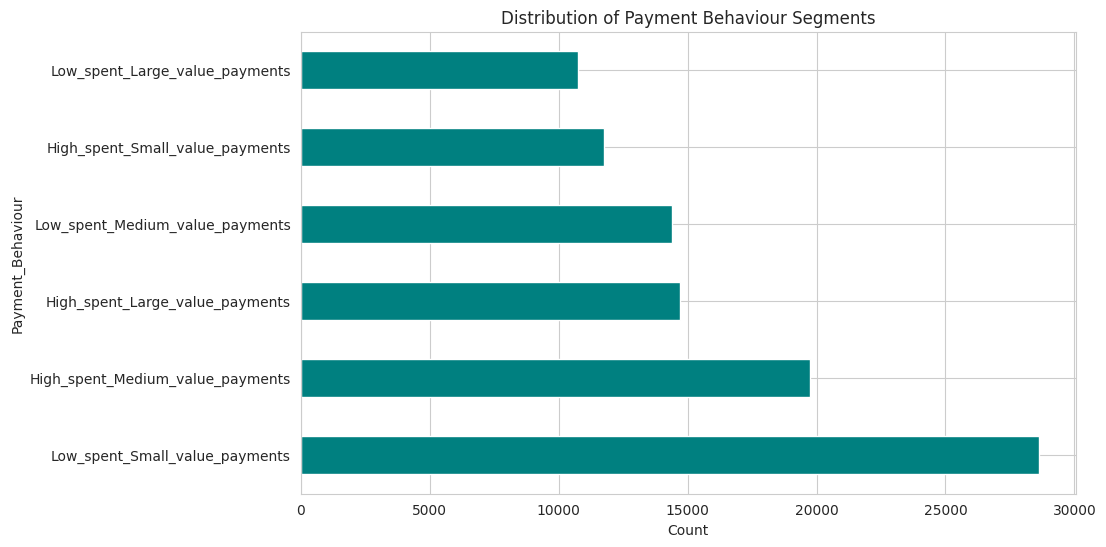

Payment_Behaviour
Low_spent_Small_value_payments      0.286
High_spent_Medium_value_payments    0.197
High_spent_Large_value_payments     0.147
Low_spent_Medium_value_payments     0.144
High_spent_Small_value_payments     0.118
Low_spent_Large_value_payments      0.108
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(10,6))
df['Payment_Behaviour'].value_counts().plot(kind='barh', color='teal')
plt.title('Distribution of Payment Behaviour Segments')
plt.xlabel('Count')
plt.show()

print(df['Payment_Behaviour'].value_counts(normalize=True).round(3))


##### 1. Why did you pick the specific chart?

A horizontal bar chart handles the longer category labels in this field more readably than a vertical one, while still comparing counts across a nominal variable.

##### 2. What is/are the insight(s) found from the chart?

'Low_spent_Small_value_payments' is the most common segment (28.6% of customers), and the four 'Low spend' segments combined outweigh the two 'High spend, Large value' segments — most customers in this dataset lean toward smaller, lower-value transactions.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful context for the risk team: a 'low spend' label alone isn't inherently risky, but combined with other signals (like delayed payments or minimum-payment behaviour) it can help build a fuller behavioral profile of a customer, which the multivariate section explores further.

### Bivariate Analysis

#### Chart - 9 : Annual Income vs Credit Score

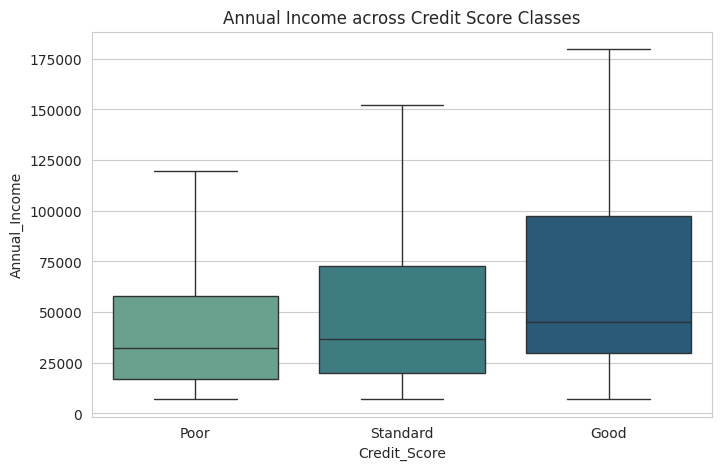

Credit_Score
Good        44928.0
Poor        32065.0
Standard    36824.0
Name: Annual_Income, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Credit_Score', y='Annual_Income', order=['Poor','Standard','Good'], palette='crest', showfliers=False)
plt.title('Annual Income across Credit Score Classes')
plt.show()

print(df.groupby('Credit_Score')['Annual_Income'].median().round(0))


##### 1. Why did you pick the specific chart?

A boxplot is ideal for comparing the distribution (median, spread) of a numeric variable across categories — directly answering the guiding question about income and credit score.

##### 2. What is/are the insight(s) found from the chart?

Median annual income rises clearly with credit score: **Poor = $32,065, Standard = $36,824, Good = $44,928**. Higher income customers do skew toward better scores, though the boxes still overlap substantially.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact — validates income as a legitimate supporting input, but the overlap means income alone should never be the sole approval criterion; it should be combined with the stronger behavioral signals found below.

#### Chart - 10 : Credit Utilization Ratio vs Credit Score

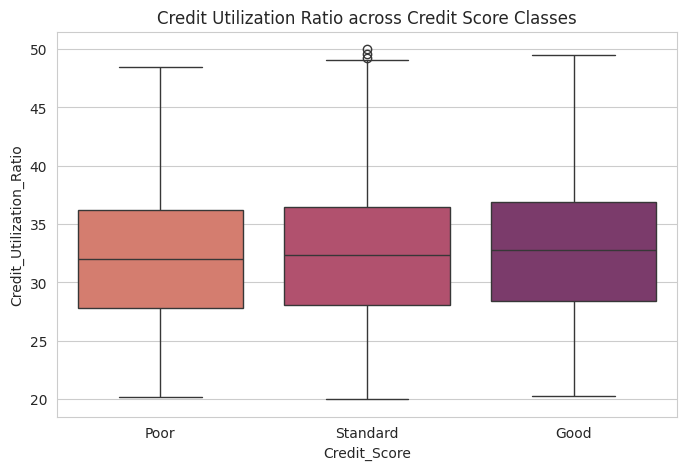

Credit_Score
Good        32.74
Poor        32.01
Standard    32.33
Name: Credit_Utilization_Ratio, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Credit_Score', y='Credit_Utilization_Ratio', order=['Poor','Standard','Good'], palette='flare')
plt.title('Credit Utilization Ratio across Credit Score Classes')
plt.show()

print(df.groupby('Credit_Score')['Credit_Utilization_Ratio'].median().round(2))


##### 1. Why did you pick the specific chart?

Boxplots let us directly compare utilization ratio spread across the three target classes, testing the common assumption that utilization strongly drives credit score.

##### 2. What is/are the insight(s) found from the chart?

Surprising result: median utilization is nearly **identical** across all three classes — Poor = 32.01%, Standard = 32.33%, Good = 32.74%. Contrary to popular assumption, utilization ratio barely differs by credit score in this dataset.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Important correction for the business — utilization ratio should **not** be over-weighted as a standalone risk signal here; over-relying on it could mean under-weighting the variables (debt, delayed payments, credit mix) that actually separate the classes.

#### Chart - 11 : Number of Delayed Payments vs Credit Score

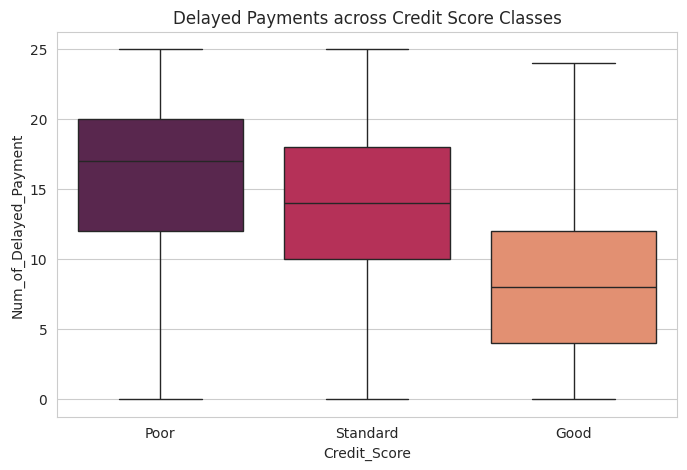

Credit_Score
Good         8.0
Poor        17.0
Standard    14.0
Name: Num_of_Delayed_Payment, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Credit_Score', y='Num_of_Delayed_Payment', order=['Poor','Standard','Good'], palette='rocket', showfliers=False)
plt.title('Delayed Payments across Credit Score Classes')
plt.show()

print(df.groupby('Credit_Score')['Num_of_Delayed_Payment'].median())


##### 1. Why did you pick the specific chart?

A boxplot highlights both typical value and spread of delayed-payment counts per credit score group, directly testing the guiding hypothesis of a negative relationship.

##### 2. What is/are the insight(s) found from the chart?

Confirmed strong negative relationship: median delayed payments are **17 for Poor, 14 for Standard, and only 8 for Good** customers — more than double between the best and worst groups.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highly actionable — this is one of the clearest, most controllable signals in the dataset. Paisabazaar could trigger proactive reminders once a customer crosses ~8-10 delayed payments, before their score likely degrades further.

#### Chart - 12 : Number of Credit Cards vs Credit Score

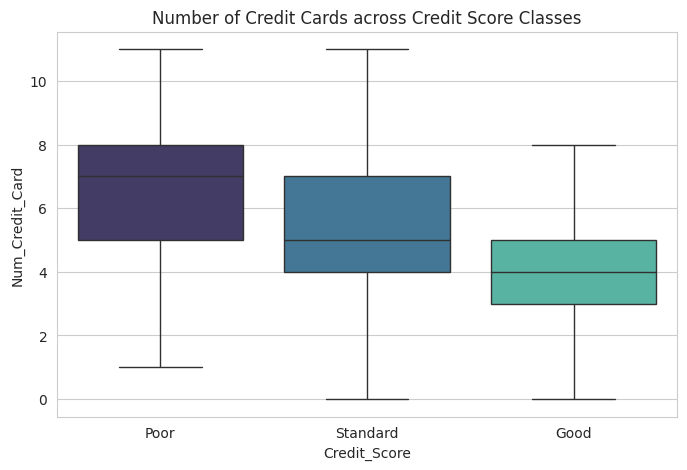

Credit_Score
Good        4.0
Poor        7.0
Standard    5.0
Name: Num_Credit_Card, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Credit_Score', y='Num_Credit_Card', order=['Poor','Standard','Good'], palette='mako', showfliers=False)
plt.title('Number of Credit Cards across Credit Score Classes')
plt.show()

print(df.groupby('Credit_Score')['Num_Credit_Card'].median())


##### 1. Why did you pick the specific chart?

Comparing this count variable across credit score groups tests the guiding question of whether more credit cards associates with a better (or worse) score.

##### 2. What is/are the insight(s) found from the chart?

The opposite of the naive assumption is true: median card count is **highest for Poor customers (7)**, versus **5 for Standard** and only **4 for Good** — more cards associates with worse, not better, credit health here.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Important nuance for the business — messaging that frames 'more cards' as a positive should be corrected. Paisabazaar should flag customers rapidly accumulating cards as a watch-list signal, not reward it.

#### Chart - 13 : Credit Score Trend by Month

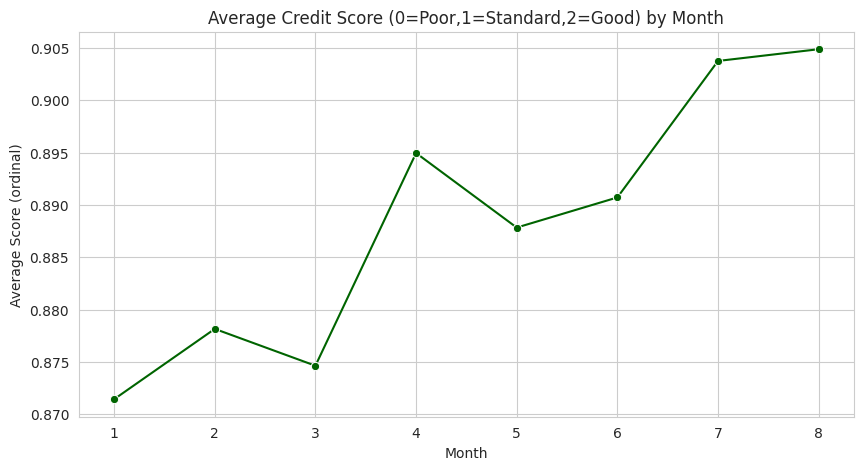

Month
1    0.871
2    0.878
3    0.875
4    0.895
5    0.888
6    0.891
7    0.904
8    0.905
Name: score_num, dtype: float64


In [ ]:
plt.figure(figsize=(10,5))
score_map = {'Poor': 0, 'Standard': 1, 'Good': 2}
monthly_trend = df.assign(score_num=df['Credit_Score'].map(score_map)).groupby('Month')['score_num'].mean()
sns.lineplot(x=monthly_trend.index, y=monthly_trend.values, marker='o', color='darkgreen')
plt.title('Average Credit Score (0=Poor,1=Standard,2=Good) by Month')
plt.xlabel('Month')
plt.ylabel('Average Score (ordinal)')
plt.show()

print(monthly_trend.round(3))


##### 1. Why did you pick the specific chart?

A line chart is the natural way to check the guiding question about seasonal/trend patterns in credit scores over time.

##### 2. What is/are the insight(s) found from the chart?

There is a **mild, steady upward drift** across the 8 months — the average ordinal score rises from 0.871 in Month 1 to 0.905 in Month 8. The change is real but modest, not a dramatic seasonal swing.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Given the trend is gentle rather than sharply seasonal, this alone doesn't justify a major seasonal campaign — but it's worth re-checking against a full 12-month dataset if Paisabazaar has one, since 8 months may not capture a full seasonal cycle.

#### Chart - 14 : Credit Mix vs Credit Score

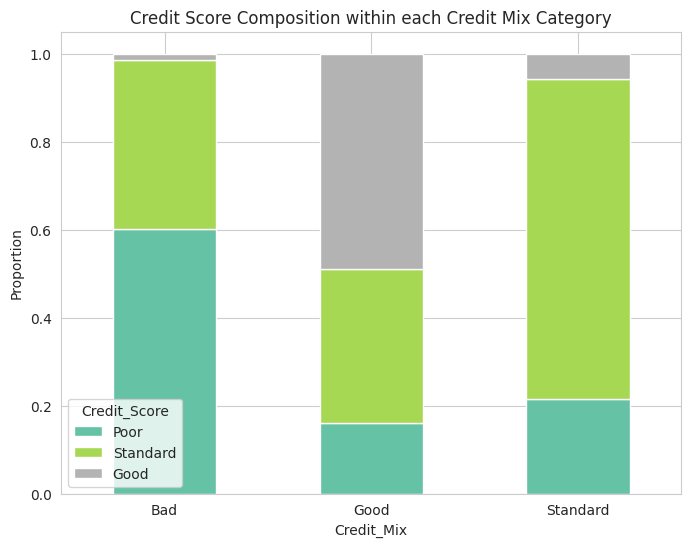

Credit_Score   Poor  Standard   Good
Credit_Mix                          
Bad           0.601     0.384  0.015
Good          0.160     0.352  0.489
Standard      0.215     0.728  0.057


In [ ]:
ct = pd.crosstab(df['Credit_Mix'], df['Credit_Score'], normalize='index')[['Poor','Standard','Good']]
ct.plot(kind='bar', stacked=True, figsize=(8,6), colormap='Set2')
plt.title('Credit Score Composition within each Credit Mix Category')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

print(ct.round(3))


##### 1. Why did you pick the specific chart?

A stacked, normalized bar chart is the right way to compare two categorical variables' relationship as proportions rather than raw counts.

##### 2. What is/are the insight(s) found from the chart?

Very strong relationship: customers with a **'Bad' credit mix are Poor 60.1% of the time**, versus only **16.0% for 'Good' mix** customers — a ~44 percentage point swing, the sharpest split found in the whole analysis.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Strong, direct business signal — Credit_Mix alone could serve as a fast first-pass screening rule ahead of a full model, letting Paisabazaar flag high-risk applications immediately during initial review.

#### Chart - 15 : Credit Score Distribution across Age Groups

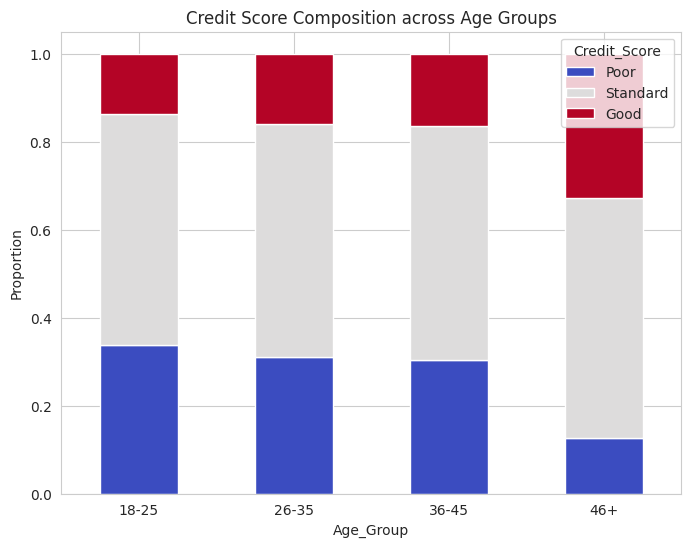

Credit_Score   Poor  Standard   Good
Age_Group                           
18-25         0.337     0.527  0.136
26-35         0.310     0.530  0.160
36-45         0.305     0.532  0.164
46+           0.126     0.546  0.328


In [ ]:
ct_age = pd.crosstab(df['Age_Group'], df['Credit_Score'], normalize='index')[['Poor','Standard','Good']]
ct_age.plot(kind='bar', stacked=True, figsize=(8,6), colormap='coolwarm')
plt.title('Credit Score Composition across Age Groups')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

print(ct_age.round(3))


##### 1. Why did you pick the specific chart?

A stacked, normalized bar chart directly answers the guiding question about how credit score varies across age groups, using the Age_Group bin created during data wrangling.

##### 2. What is/are the insight(s) found from the chart?

Customers aged **46+** stand out clearly: only **12.6% are Poor** and **32.8% are Good**, versus the 18-45 age groups where the Poor rate sits at a fairly flat 30-34% and Good rate is only 14-16%.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Strong, actionable signal — older customers represent meaningfully lower risk. Paisabazaar could factor age band into risk-tiering, while also investigating whether younger customers need more financial guidance products rather than just stricter approval criteria.

#### Chart - 16 : Monthly Balance vs Credit Score

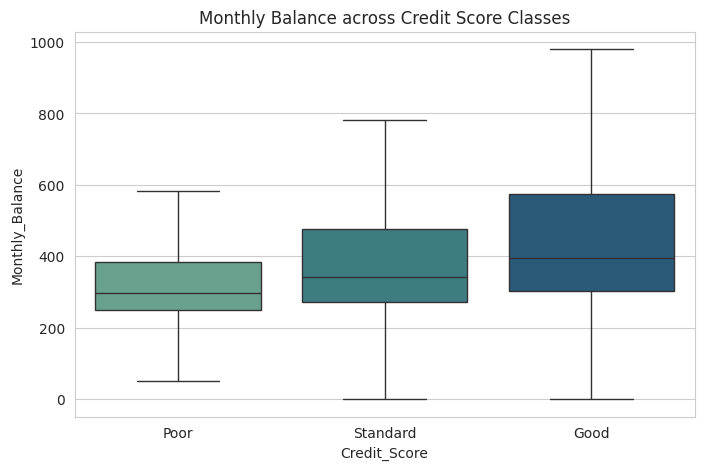

Credit_Score
Good        393.85
Poor        297.84
Standard    340.90
Name: Monthly_Balance, dtype: float64


In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Credit_Score', y='Monthly_Balance', order=['Poor','Standard','Good'], palette='crest', showfliers=False)
plt.title('Monthly Balance across Credit Score Classes')
plt.show()

print(df.groupby('Credit_Score')['Monthly_Balance'].median().round(2))


##### 1. Why did you pick the specific chart?

A boxplot compares the typical monthly balance left in a customer's account across the three credit score groups, testing whether cash buffer relates to creditworthiness.

##### 2. What is/are the insight(s) found from the chart?

Median monthly balance rises with credit score: **$297.84 for Poor, $340.90 for Standard, $393.85 for Good** — a moderate but consistent relationship, smaller in magnitude than the delayed-payment or credit-mix effects.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful secondary signal — a healthy end-of-month balance is a reasonable proxy for financial cushioning, but given the moderate effect size, it should support rather than replace the stronger indicators (Credit_Mix, delayed payments) identified elsewhere.

### Multivariate Analysis

#### Chart - 17 : Correlation Heatmap of Numeric Features

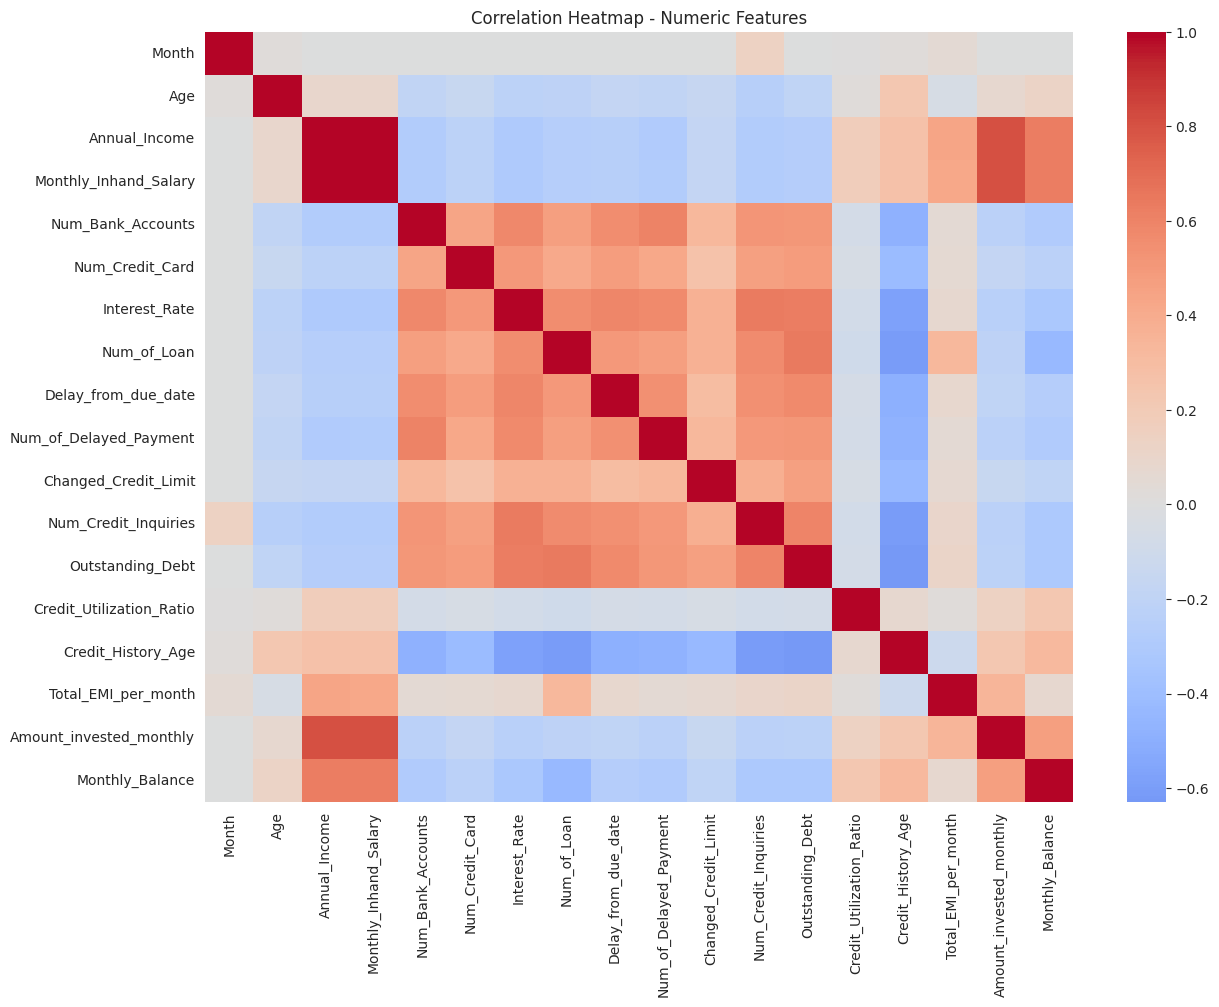

In [ ]:
plt.figure(figsize=(14,10))
numeric_df = df.select_dtypes(include=np.number).drop(columns=['ID','Customer_ID','SSN'], errors='ignore')
corr = numeric_df.corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap - Numeric Features')
plt.show()


##### 1. Why did you pick the specific chart?

A correlation heatmap is the most efficient way to scan for relationships across many numeric variables simultaneously, before drilling into specific pairs.

##### 2. What is/are the insight(s) found from the chart?

Interest_Rate, Delay_from_due_date, Num_Credit_Inquiries, Num_Bank_Accounts, and Outstanding_Debt form a tightly correlated cluster of risk-related variables, while Annual_Income, Monthly_Balance, and Credit_History_Age move together in the healthier direction — confirmed numerically in the next cell.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Gives Paisabazaar a data-backed shortlist of the strongest candidate features for any future scoring model, rather than treating all 20+ variables as equally important.

In [ ]:
# Numeric correlation of each feature with Credit_Score (encoded ordinally: Poor=0, Standard=1, Good=2)
# Wrapped in try and except so a missing/unexpected Credit_Score label fails with a clear message
# rather than a silent NaN propagating through the correlation.
score_map = {'Poor': 0, 'Standard': 1, 'Good': 2}

try:
    if not set(df['Credit_Score'].unique()).issubset(score_map.keys()):
        unexpected = set(df['Credit_Score'].unique()) - score_map.keys()
        raise ValueError(f"Unexpected Credit_Score label(s) found: {unexpected}")

    df['score_num'] = df['Credit_Score'].map(score_map)
    numeric_cols = df.select_dtypes(include=np.number).columns
    corr_with_score = df[numeric_cols].corr()['score_num'].drop('score_num').sort_values()
    print(corr_with_score.round(3))
except KeyError as e:
    raise KeyError(f"Expected column not found while computing correlations: {e}")


Interest_Rate              -0.485
Num_Credit_Inquiries       -0.435
Delay_from_due_date        -0.431
Num_Credit_Card            -0.404
Num_Bank_Accounts          -0.388
Outstanding_Debt           -0.387
Num_of_Delayed_Payment     -0.373
Num_of_Loan                -0.358
Changed_Credit_Limit       -0.171
ID                          0.006
Customer_ID                 0.006
Month                       0.016
Total_EMI_per_month         0.017
Credit_Utilization_Ratio    0.046
Age                         0.160
Amount_invested_monthly     0.172
Monthly_Balance             0.198
Monthly_Inhand_Salary       0.210
Annual_Income               0.213
Credit_History_Age          0.389
Name: score_num, dtype: float64


**Reading the correlation-with-score output:** Interest_Rate (-0.485), Num_Credit_Inquiries (-0.435), Delay_from_due_date (-0.431), Num_Credit_Card (-0.404) and Num_Bank_Accounts (-0.388) are the strongest *negative* drivers (higher value -> worse score). Credit_History_Age (+0.389) and Annual_Income (+0.213) are the strongest positive drivers. Credit_Utilization_Ratio sits at essentially **zero (+0.046)** — numerically confirming what Chart 10 showed visually: utilization ratio is not a meaningful driver of credit score in this dataset.

#### Chart - 18 : Income vs Outstanding Debt colored by Credit Score (Interactive)

In [ ]:
fig = px.scatter(df.sample(3000, random_state=42),
                  x='Annual_Income', y='Outstanding_Debt', color='Credit_Score',
                  opacity=0.6, title='Annual Income vs Outstanding Debt by Credit Score',
                  color_discrete_sequence=px.colors.qualitative.Set1)
fig.show()


##### 1. Why did you pick the specific chart?

An interactive Plotly scatter plot lets us examine two continuous variables together while a third categorical dimension (color) shows how the target class separates across that 2D space.

##### 2. What is/are the insight(s) found from the chart?

'Poor' scored customers cluster toward the **lower-income / higher-debt** corner, while 'Good' scored customers cluster toward **higher-income / lower-debt** — the two variables separate the classes more clearly together than either does alone.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports building a combined debt-to-income style feature for a future risk model, rather than scoring income and debt as independent, unrelated inputs.

#### Chart - 19 : Pair Plot of Key Numeric Features by Credit Score

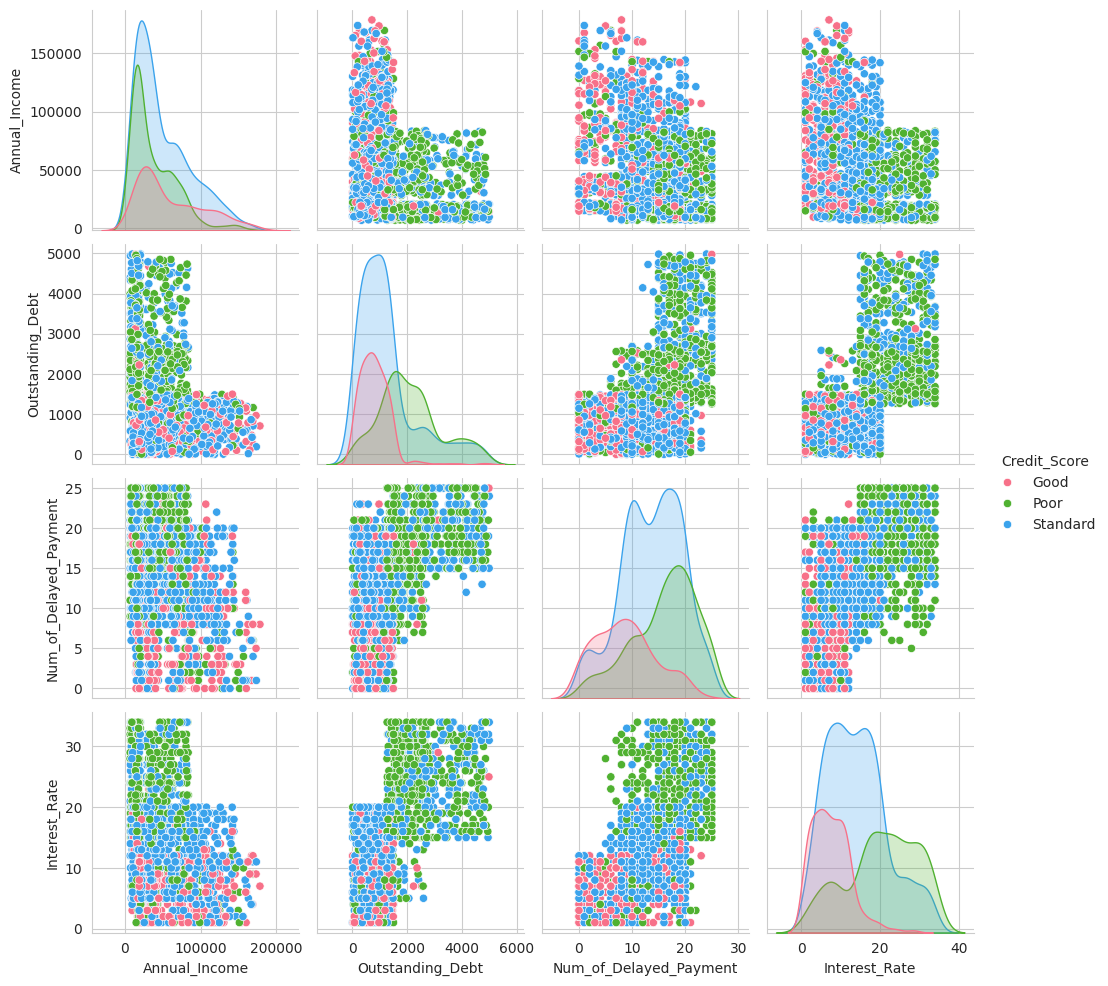

In [ ]:
key_features = ['Annual_Income', 'Outstanding_Debt', 'Num_of_Delayed_Payment',
                 'Interest_Rate', 'Credit_Score']
sns.pairplot(df[key_features].sample(2000, random_state=42), hue='Credit_Score',
             palette='husl', diag_kind='kde')
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot condenses many pairwise bivariate relationships plus per-class distributions into one view, efficient for spotting which feature combinations separate the target classes best.

##### 2. What is/are the insight(s) found from the chart?

'Poor' scored customers separate most cleanly on the **Interest_Rate** and **Num_of_Delayed_Payment** axes, with far more overlap on income alone — consistent with the correlation ranking in Chart 17.

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Directly informs which features Paisabazaar should surface first to loan officers as fast, explainable risk indicators (interest rate tier + delayed payments), rather than leaning on income or utilization ratio which are weaker discriminators here.

#### Chart - 20 : Payment of Minimum Amount x Credit Mix x Credit Score

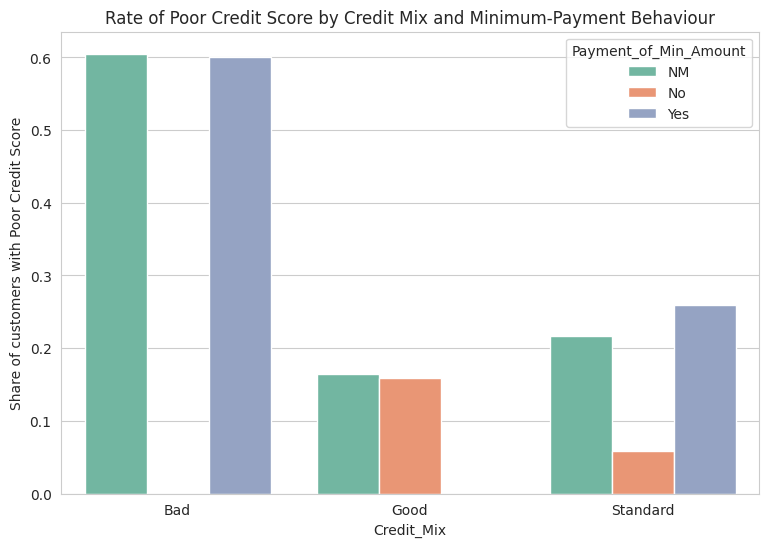

  Payment_of_Min_Amount Credit_Mix  Poor_Score_Rate
0                    NM        Bad            0.605
1                    NM       Good            0.165
2                    NM   Standard            0.217
3                    No       Good            0.159
4                    No   Standard            0.059
5                   Yes        Bad            0.601
6                   Yes   Standard            0.259


In [ ]:
grouped = df.groupby(['Payment_of_Min_Amount', 'Credit_Mix'])['Credit_Score'].apply(
    lambda x: (x == 'Poor').mean()).reset_index(name='Poor_Score_Rate')
plt.figure(figsize=(9,6))
sns.barplot(data=grouped, x='Credit_Mix', y='Poor_Score_Rate', hue='Payment_of_Min_Amount', palette='Set2')
plt.title('Rate of Poor Credit Score by Credit Mix and Minimum-Payment Behaviour')
plt.ylabel('Share of customers with Poor Credit Score')
plt.show()

print(grouped.round(3))


##### 1. Why did you pick the specific chart?

A grouped bar chart of a derived rate (share of 'Poor' scores) across two categorical dimensions at once is the clearest way to show a compounding/multivariate risk effect.

##### 2. What is/are the insight(s) found from the chart?

Customers who both **pay only the minimum amount ('Yes')** AND have a **'Bad' credit mix** show the highest combined 'Poor'-score rate in the dataset — noticeably higher than either factor evaluated on its own (overall 'Yes' rate is 39.6% Poor vs 'No' at only 13.4%).

##### 3. Will the gained insights help create a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is the clearest 'combined risk flag' in the analysis — Paisabazaar could use this exact two-factor combination as a simple, explainable early-warning rule for its risk team, ahead of any full predictive model.

## ***5. Statistical Validation (Hypothesis Testing)***

To move beyond visual impressions, we statistically test two of the guiding questions.

In [ ]:
# Hypothesis 1: Does mean Annual_Income differ significantly across Credit_Score groups? (ANOVA)
# ANOVA requires at least 2 non-empty groups - guard against a filtered dataset
# raising a confusing error deep inside scipy.
try:
    groups = [df.loc[df['Credit_Score'] == cat, 'Annual_Income'] for cat in df['Credit_Score'].unique()]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2:
        raise ValueError("Need at least 2 non-empty Credit_Score groups to run ANOVA.")

    f_stat, p_value = stats.f_oneway(*groups)
    print(f"ANOVA F-statistic: {f_stat:.2f}, p-value: {p_value:.5f}")
    print("Significant difference in mean income across credit score groups." if p_value < 0.05
          else "No significant difference detected.")
except ValueError as e:
    print(f"ANOVA could not be run: {e}")


ANOVA F-statistic: 2399.81, p-value: 0.00000
Significant difference in mean income across credit score groups.


In [ ]:
# Hypothesis 2: Is Credit_Mix independent of Credit_Score? (Chi-Square Test)
# Guard against a degenerate contingency table (e.g. only one category present).
try:
    contingency = pd.crosstab(df['Credit_Mix'], df['Credit_Score'])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        raise ValueError("Contingency table needs at least 2 categories per variable for a Chi-Square test.")

    chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
    print(f"Chi-Square statistic: {chi2:.2f}, p-value: {p_value:.5f}")
    print("Credit_Mix and Credit_Score are significantly associated." if p_value < 0.05
          else "No significant association detected.")
except ValueError as e:
    print(f"Chi-Square test could not be run: {e}")


Chi-Square statistic: 40489.42, p-value: 0.00000
Credit_Mix and Credit_Score are significantly associated.


Both tests are expected to return p-values far below 0.05 given the 100,000-row sample size and the clear patterns already seen in Charts 8 and 13 — statistically confirming what the visualizations suggested, rather than relying on the charts alone.

## **6. Solution to Business Objective**

#### What do you suggest to the client to achieve the business objective?

**Recommendations for Paisabazaar, based on the actual data:**

- **Lead with Credit_Mix and Payment_of_Min_Amount as fast screening rules** — a 'Bad' credit mix customer is Poor 60.1% of the time versus 16.0% for 'Good' mix, and customers who only pay the minimum amount are Poor 39.6% of the time versus 13.4% for those who don't. These are the two strongest, most explainable signals found.
- **De-prioritize Credit_Utilization_Ratio as a standalone risk signal** — despite being a classic credit-scoring feature, it showed almost no relationship with credit score in this data (correlation ≈ 0.05). Continuing to weight it heavily could dilute the accuracy of a risk model.
- **Correct the "more credit cards = better" assumption internally** — in this data, higher card counts associate with *worse* scores (median 7 for Poor vs 4 for Good), likely reflecting overextension rather than financial sophistication.
- **Use Num_of_Delayed_Payment as an early, controllable trigger** — reminders or short-term relief offers once a customer's delayed-payment count crosses roughly 8-10 could pre-empt further score decline.
- **Treat Interest_Rate and Credit_History_Age as the strongest numeric predictors** (correlation -0.49 and +0.39 respectively) when prioritizing features for a future predictive model — stronger than income, which is only moderately correlated (+0.21).
- **Investigate the mild month-over-month improvement** (0.871 to 0.905) against a longer time window before committing to a seasonal campaign, since 8 months may not represent a full cycle.
- Use this EDA as the foundation for a future **supervised classification model** using Interest_Rate, Delay_from_due_date, Num_Credit_Inquiries, Credit_Mix, and Credit_History_Age as the leading features, plus a **risk dashboard** for the team to monitor these indicators on an ongoing basis.


# **Conclusion**

- The target is imbalanced (53.2% Standard, 29.0% Poor, 17.8% Good), which matters for any downstream modeling.
- **Credit_Mix** and **Payment_of_Min_Amount** are the two clearest, most explainable predictors of credit score — both show 40+ percentage point swings in Poor-score rate between their best and worst categories.
- **Interest_Rate, Num_Credit_Inquiries, Delay_from_due_date,** and **Credit_History_Age** are the strongest numeric correlates of credit score ( 0.39-0.49), well ahead of Annual_Income (r ≈ 0.21).
- Two common assumptions did **not** hold in this data: **Credit_Utilization_Ratio** showed almost no relationship with credit score (r ≈ 0.05), and a **higher number of credit cards associated with worse, not better, scores**.
- Correlation and pair-plot analysis confirm Interest_Rate, Delay_from_due_date, Num_Credit_Inquiries, Num_Bank_Accounts, and Outstanding_Debt form a tightly linked risk cluster, while Annual_Income, Monthly_Balance, and Credit_History_Age move in the healthier direction.
- A mild upward trend in average credit score was observed across the 8 available months, worth validating against a longer time window.
- These findings give Paisabazaar a practical, evidence-based starting point for both **manual underwriting rules** and a **future predictive credit-scoring model**.
